In [6]:
import numpy as np
import matplotlib.pyplot as plt

### 1a.

We know that:

$$
SHF + LHF+SW_{net}+LW_{net}+G=0
$$

The question states that there is a zero ground heat flux, so $G = 0$. Furthermore, the constant net radiation flux at the ground surface is given, which means:

$$
SW_{net}+LW_{net} = 400 [W/m^2]
$$

Therefore, the sum of the latent en sensible heat fluxes must be equal to $-400 [W/m^2]$.

In this situation, the values for SHF and LHF can range between 0 and -400, as long as their sum is still equal to $-400 [W/m^2]$.

### 1b.

In this scenario, there is no evaporation, so we can say that $LHF = 0$ and therefore $SHF = -400$. With that, we can calculate $\overline{w'T'}$:

$$
\overline{w'T'}= \frac{SHF}{\rho c_p}
$$

which gives a value of $-0.332 [mK/s]$. With this value, we can calculate the change in temperature over time using the following formula:

$$
\frac{\partial \overline{T}}{\partial t} = -\frac{\partial \overline{w'T'}}{\partial z}
$$

Since there is no ground heat flux, $\partial \overline{w'T'}$ at the ground will be equal to zero, which then gives a final answer of $-1.194 K/h$

In [7]:
# Define initla parameters
density = 1.2 #kg/m^3
h = 1000 #m
SHF = -400 # No evaporation, so LHF = 0, W/m^2
cp = 1005 #?

# Calculate wT
wT__ = SHF/(density*cp)
print(f"wT__ value: {wT__:.3f} mK/s")

# Calculate the change in temp. over time
dTdt = -(0-wT__)/h
print(f"Heating rate at z = {h} m: {dTdt*3600:.3f} K/h")

wT__ value: -0.332 mK/s
Heating rate at z = 1000 m: -1.194 K/h


### 1c.

# YO OULA I THINK THIS ONE IS WRONG, THE FORMULA FOR QV IS THE FORMULA FOR Q_SAT I THINK LOOK AT CLASS 2 SLIDE 20

We first the define the formula for $e_{sat}$:

$$
e_{sat,z} = 610.78 e^{\frac{17.2694(T - 273.16)}{T - 35.86}}
$$

We now want to calculate the change of the saturation specific humididty at the top of the boundary layer. For that we use the following equation:

$$
q_v = \frac{R_d}{R_v}\frac{e_{sat}}{p} [1]
$$

It is assumed that the pressure is constant, which we can calculate using:

$$
p = \rho R_d T_0 [2]
$$

Where $T_0$ is the initial temperature.

We can rewrite equation [1] as:

$$
\frac{\partial}{\partial t}q_v =\frac{\partial}{\partial t} \frac{R_d}{R_v}\frac{e_{sat}}{p} [3.1]
$$

$$
\frac{\partial q_v}{\partial t} = \frac{R_d}{R_v}\frac{1}{p} \frac{\partial e_{sat}}{\partial t}[3.2]
$$

$$
\frac{\partial q_v}{\partial t} = \frac{R_d}{R_v}\frac{1}{p}   \frac{ e_{sat}(T_1) - e_{sat}(T_0)}{T_1-T_0}[3.3]
$$

Using equation 3.3, we find a change of $8.842 [g/kg/h]$

In [8]:
# Define parameters and constants
Rv = 461.5
Rd = 287.04

T0 = 293 # Default value
T1 = T0 + dTdt # Based on value from 1b

# Define e_sat function, which only depends on T
def e_sat(T):
    esat = 610.78*np.exp(17.2694 * (T -273.16) / (T - 35.86))
    return esat

dqdt=((Rd/Rv)*(e_sat(T1)-e_sat(T0))/(density*T0*Rd))/(T1-T0)*1000
print(f"change in q_v: {dqdt:.3f} g/kg/h")

change in q_v: 0.884 g/kg/h


### 1d.



In this scenario, $LHF = -400$ and $SHF = 0$. With the $LHF$ we can now use the following formula:

$$
LHF = \rho \lambda_l \overline{w'q_v'} [1]
$$

where $\lambda_l$ is the latent heat of vaporization for water, which is equal to $2.26\cdot 10^6 [J/kg]$.

We rewrite equation 1 to:

$$
\overline{w'q_v'} = \frac{LHF}{\rho \lambda_l} [2]
$$

We can then say that:

$$
\frac{\partial\overline{w'q_v'}}{\partial z} = \frac{0-\frac{LHF}{\rho \lambda_l}}{0-h} = \frac{\partial \overline{q_v}}{\partial t}
$$

When we calculate this, we get a value of $0.531 [g/kg/h]$

In [9]:
# New scenario value
LHF = -400

# Constant
lambda_l = 2.26e6

# Calculate wqv__
wqv__ = LHF/(density*lambda_l)

# Calcualte final answer
dq_vdt = (0 - wqv__) / (0 - h) * 1000 * 3600
print(f"dqv/dt = {-dq_vdt:.3f} g/kg/h")

dqv/dt = 0.531 g/kg/h


### 1e.

We now assume the following two things:

$$
LHF = \rho \lambda_l \overline{w'q_v'} ≠ 0 [1.1]
$$

$$
SHF= \rho c_p \overline{w'T'} ≠ 0 [1.2]
$$

We now want a  constant relative humidity at the top of the atmosphere, so:

$$
\frac{\partial RH}{\partial t}=0 [2]
$$

Where 
$$
RH = \frac{e_v}{e_{sat}} [3.1]
$$

$$
e_v = \frac{q_v p R_v}{(1-q_v)R_d} [3.2]
$$

$$
e_{sat,z} = 610.78 e^{\frac{17.2694(T - 273.16)}{T - 35.86}} [3.3]
$$


We know that we have a non-zero heating rate, since $SHF ≠ 0$, we know that our saturated water pressure (equation 3.3)will increase. Thus to maintain a constant relative humidity, we must compensate with the water vapor pressure (equation 3.2) which depends on q_v, which is the moistening rate (?). We determined in question 1.d that the moistening rate also changes with time as long as $LHF ≠ 0$,. which it is here. We thus need to find a value for $SHF$ and $LHF$ where the change in $e_v$ is the same as the change in $e_{sat}$ over time. We will do this by taking a numerical approach, which gives us:

$$
\frac{\partial RH}{\partial t} = \frac{\frac{e_{v,1}}{e_{sat,1}}-\frac{e_{v,0}}{e_{sat,0}}}{t_1-t_0} = 0
$$

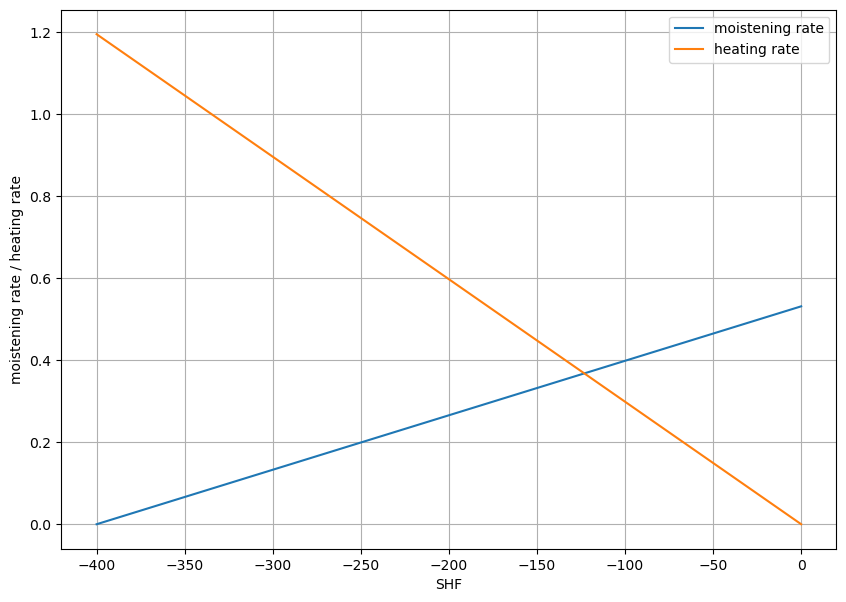

In [31]:
# Define initla parameters
density = 1.2 #kg/m^3
h = 1000 #m
SHF = np.linspace(0,-400) # No evaporation, so LHF = 0, W/m^2
cp = 1005 #?

# Calculate the change in temp. over time
dTdt = -(0-wT__)/h*3600



# New scenario value
LHF = SHF[::-1] # inverse of SHF

# Constant
lambda_l = 2.26e6

# Calculate wqv__
wqv__ = LHF/(density*lambda_l)

# Calcualte final answer
dq_vdt = (0 - wqv__) / (0 - h) * 1000 * 3600

plt.figure(figsize=(10,7))

plt.plot(SHF,-dq_vdt,label = 'moistening rate')
plt.plot(SHF,-dTdt,label = 'heating rate')

plt.xlabel("SHF")
plt.ylabel("moistening rate / heating rate")

plt.grid()
plt.legend()

# OULA DONT LOOK FURTHER I PRACTICALLY GAVE UP

In [100]:
def q_sat_SHF(SHF):

    density = 1.2 #kg/m^3
    h = 1000 #m
    cp = 1005 #?

    # Calculate wT
    wT__ = SHF/(density*cp)

    # Calculate the change in temp. over time
    dTdt = -(0-wT__)/h*3600

    T0 = 293 # Default value
    T1 = T0 + dTdt # Based on value from 1b

    d_qs = ((Rd/Rv)*(e_sat(T1)-e_sat(T0))/(density*T0*Rd))/(T1-T0)*1000
    return d_qs

def q_v_SHF(SHF):
    # New scenario value
    LHF = -400-SHF

    # Constant
    lambda_l = 2.26e6

    # Calculate wqv__
    wqv__ = LHF/(density*lambda_l)

    # Calcualte final answer
    dq_vdt = (0 - wqv__) / (0 - h) * 1000 * 3600
    return -dq_vdt

In [98]:
q_sat_SHF(np.linspace(-400,0))

/var/folders/k9/db40v6y15jq4qmgtynngdxrm0000gn/T/ipykernel_77969/3337608849.py:16: RuntimeWarning: invalid value encountered in divide
  d_qs = ((Rd/Rv)*(e_sat(T1)-e_sat(T0))/(density*T0*Rd))/(T1-T0)*1000


array([0.85615073, 0.85671389, 0.85727749, 0.8578415 , 0.85840593,
       0.85897079, 0.85953607, 0.86010177, 0.86066789, 0.86123444,
       0.86180141, 0.8623688 , 0.86293662, 0.86350486, 0.86407353,
       0.86464262, 0.86521214, 0.86578209, 0.86635245, 0.86692325,
       0.86749447, 0.86806612, 0.8686382 , 0.8692107 , 0.86978363,
       0.87035699, 0.87093077, 0.87150499, 0.87207963, 0.8726547 ,
       0.8732302 , 0.87380613, 0.87438249, 0.87495929, 0.87553651,
       0.87611416, 0.87669224, 0.87727076, 0.8778497 , 0.87842908,
       0.87900889, 0.87958913, 0.88016981, 0.88075092, 0.88133246,
       0.88191443, 0.88249684, 0.88307969, 0.88366296,        nan])

In [99]:
q_v_SHF(SHF)

array([-0.53097345, -0.52013726, -0.50930107, -0.49846487, -0.48762868,
       -0.47679249, -0.46595629, -0.4551201 , -0.44428391, -0.43344772,
       -0.42261152, -0.41177533, -0.40093914, -0.39010294, -0.37926675,
       -0.36843056, -0.35759437, -0.34675817, -0.33592198, -0.32508579,
       -0.31424959, -0.3034134 , -0.29257721, -0.28174101, -0.27090482,
       -0.26006863, -0.24923244, -0.23839624, -0.22756005, -0.21672386,
       -0.20588766, -0.19505147, -0.18421528, -0.17337909, -0.16254289,
       -0.1517067 , -0.14087051, -0.13003431, -0.11919812, -0.10836193,
       -0.09752574, -0.08668954, -0.07585335, -0.06501716, -0.05418096,
       -0.04334477, -0.03250858, -0.02167239, -0.01083619, -0.        ])